# Prophet. Часть 1: устройство модели

Prophet — это **байесовская регрессия на признаках времени**: кусочно-линейный тренд + Фурье-сезонности + праздники + регрессоры, с регуляризующими априорными распределениями.

План:
1. Мотивация и «зацепка»: 3 строки кода → прогноз и компоненты. Что внутри?
2. Формализация: из каких признаков собирается прогноз (и воспроизводим `predict` руками).
3. Обучение: Stan-модель, приоры ⇔ L1/L2, сборка модели через `sklearn`.
4. Прогноз и интервалы: откуда берётся неопределённость и когда она врёт.
5. Сводная таблица гиперпараметров.

Источники: туториалы документации ([quick start](https://facebook.github.io/prophet/docs/quick_start.html), uncertainty intervals, outliers), статья Taylor & Letham (2017) «Forecasting at scale», исходники `prophet/python/stan/prophet.stan` и `prophet/forecaster.py`.

In [1]:
import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from prophet import Prophet
from prophet.plot import add_changepoints_to_plot
from sklearn.linear_model import Lasso, LinearRegression

logging.getLogger("cmdstanpy").disabled = True  # прячем логи Stan
plt.rcParams["figure.figsize"] = (12, 4)

/Users/a.p.chikov/PycharmProjects/Временные ряды/Семинары/8/.venv/lib/python3.11/site-packages/joblib/_multiprocessing_helpers.py:44: UserWarning: [Errno 1] Operation not permitted.  joblib will operate in serial mode
  warnings.warn("%s.  joblib will operate in serial mode" % (e,))


## 1. Мотивация

**Forecasting at scale.** Prophet создан в Facebook под типичную бизнес-задачу: рядов много, а аналитиков с глубокой экспертизой во временных рядах мало. Поэтому модель:
- работает «из коробки» на дневных/почасовых рядах с сезонностями и праздниками;
- настраивается ручками **в терминах предметной области**: «здесь мог быть излом тренда», «рынок насыщается на уровне X», «вот список праздников», «сезонность слишком гибкая».

**Чем Prophet отличается от ETS / ARIMA / TBATS.** Те модели — авторегрессионные (state space): прогноз строится из последних наблюдений. Prophet — это **подгонка кривой по времени** (curve fitting): $y$ регрессируется на функции от даты $t$.

| | ETS / ARIMA / TBATS | Prophet |
|---|---|---|
| Что на входе модели | прошлые значения ряда | признаки даты $t$ |
| Пропуски, нерегулярная сетка | мешают | не мешают — просто нет строки |
| Стационарность | нужна (ARIMA) | не нужна |
| Последние наблюдения | сильно влияют на прогноз | влияют не больше остальных |
| Автокорреляция остатков | моделируется | **не моделируется** |

### Зацепка: прогноз в три строки

Пример из quick start — логарифм дневных просмотров страницы Википедии о Пейтоне Мэннинге (квотербек NFL). Prophet ждёт датафрейм с колонками `ds` (дата) и `y` (значение).

In [2]:
df = pd.read_csv("data/example_wp_log_peyton_manning.csv", parse_dates=["ds"])
df.head()

,ds,y
0,2007-12-10,9.590761
1,2007-12-11,8.519590
2,2007-12-12,8.183677
3,2007-12-13,8.072467
4,2007-12-14,7.893572


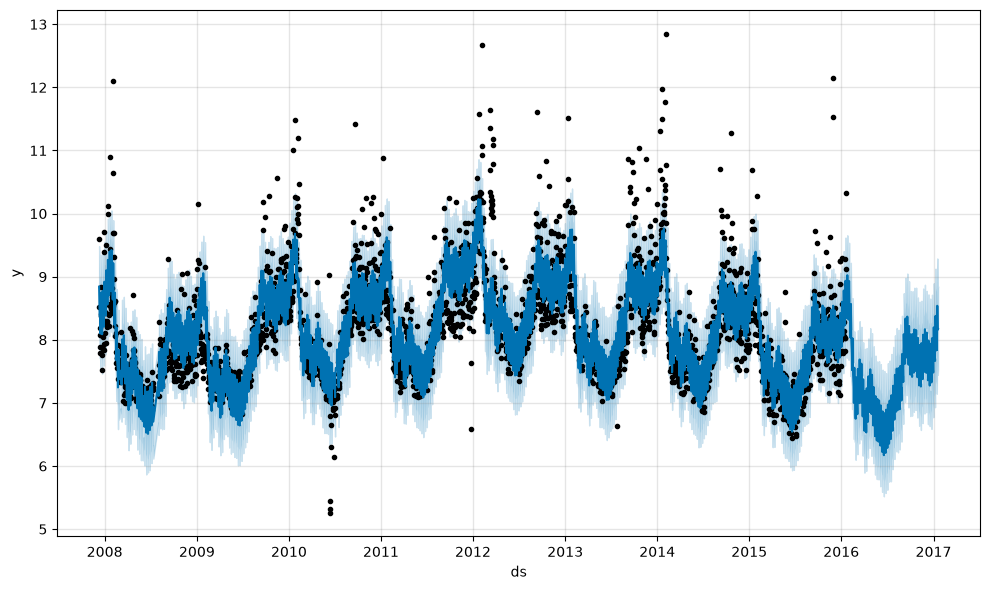

In [3]:
m = Prophet().fit(df)
future = m.make_future_dataframe(periods=365)
forecast = m.predict(future)

fig = m.plot(forecast)

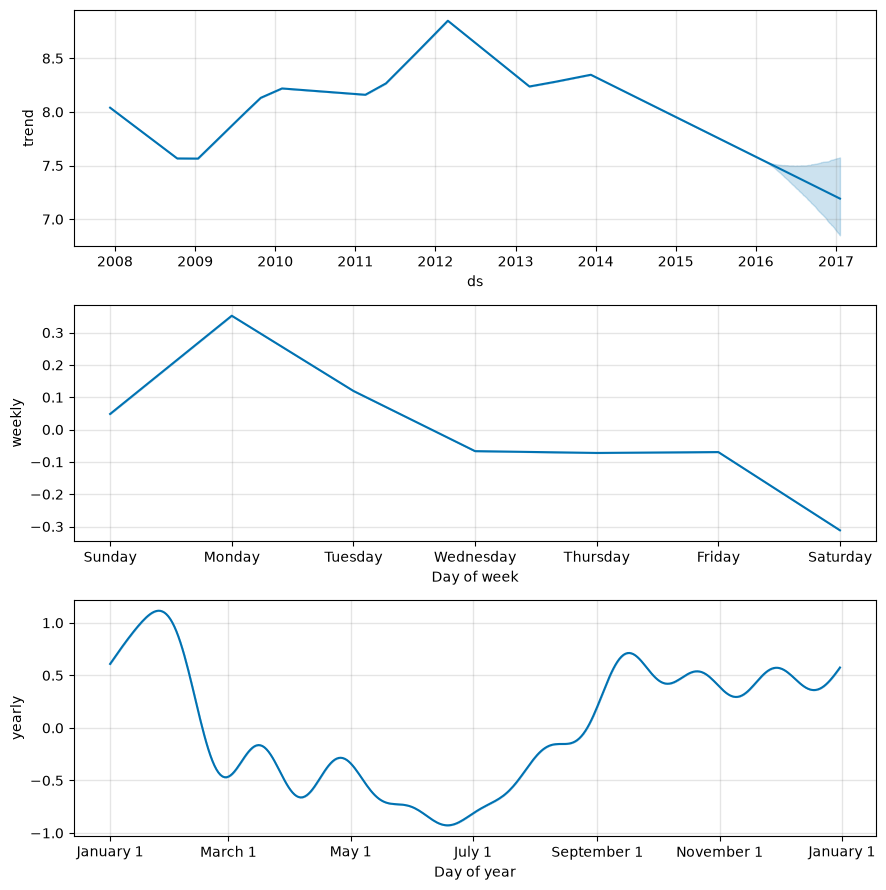

In [4]:
fig = m.plot_components(forecast)

Прогноз разложен на понятные компоненты: тренд + недельная + годовая сезонность. Появляются вопросы:
- почему тренд — ломаная и где у него изломы?
- из чего «нарисованы» гладкие сезонные кривые?
- что значит обучение и какие параметры оцениваются?
- почему полоса неопределённости расширяется в будущем?

Все столбцы прогноза — это компоненты модели и их интервалы:

In [5]:
forecast[["ds", "trend", "weekly", "yearly", "yhat", "yhat_lower", "yhat_upper"]].tail()

,ds,trend,weekly,yearly,yhat,yhat_lower,yhat_upper
3265,2017-01-15,7.196238,0.048300,0.969740,8.214278,7.542188,8.932368
3266,2017-01-16,7.195221,0.352284,0.991794,8.539300,7.805136,9.289199
3267,2017-01-17,7.194205,0.119613,1.012907,8.326725,7.613455,9.113573
3268,2017-01-18,7.193189,-0.066664,1.032873,8.159399,7.446872,8.821427
3269,2017-01-19,7.192173,-0.072266,1.051448,8.171355,7.521980,8.849358


## 2. Формализация

Аддитивная модель:
$$y(t) = g(t) + s(t) + h(t) + \beta^\top x(t) + \varepsilon_t, \qquad \varepsilon_t \sim N(0, \sigma^2),$$
мультипликативная (`seasonality_mode='multiplicative'`): $y(t) = g(t)\,\big(1 + s(t) + h(t) + \beta^\top x(t)\big) + \varepsilon_t$.

- $g(t)$ — тренд,
- $s(t)$ — сезонности,
- $h(t)$ — праздники и события,
- $x(t)$ — внешние регрессоры.

### 2.1. Тренд $g(t)$: кусочно-линейная функция

Заранее задаётся сетка из $S$ **кандидатов** в изломы $s_1 < \dots < s_S$: по умолчанию `n_changepoints=25` точек равномерно на первых `changepoint_range=0.8` истории. В точке $s_j$ наклон меняется на $\delta_j$:
$$g(t) = \big(k + a(t)^\top \delta\big)\, t + \big(m + a(t)^\top \gamma\big), \qquad a_j(t) = [t \ge s_j], \quad \gamma_j = -s_j \delta_j.$$

Сдвиги $\gamma_j$ подобраны так, чтобы ломаная была непрерывной. Если раскрыть скобки, получается совсем простая формула — **линейный сплайн**:
$$g(t) = m + k\,t + \sum_{j=1}^{S} \delta_j \max(0,\; t - s_j).$$
То есть тренд — это линейная регрессия на «шарнирные» признаки $\max(0, t - s_j)$, а $\delta_j$ — их коэффициенты.

Есть ещё логистический тренд с насыщением (`growth='logistic'`, колонки `cap`/`floor`) и постоянный (`growth='flat'`) — их разберём в следующем ноутбуке.

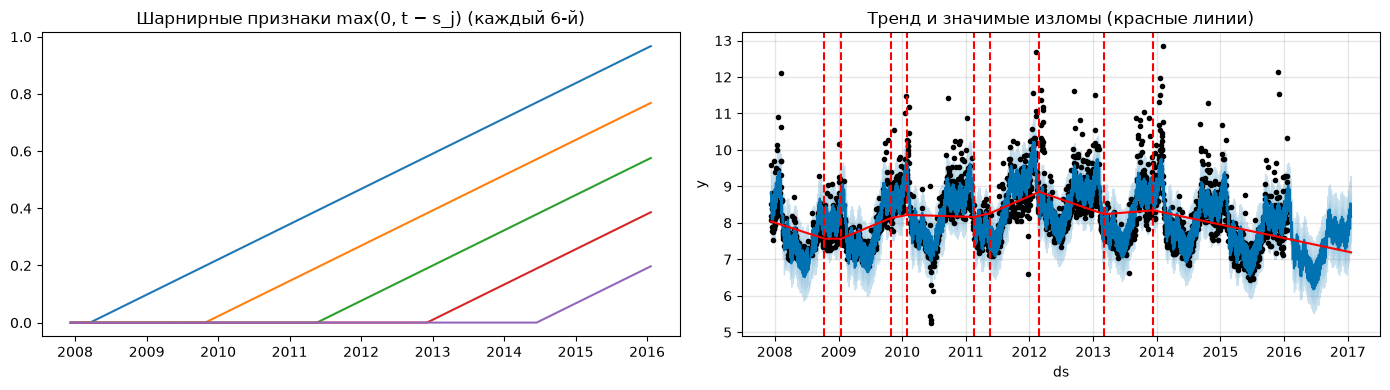

In [6]:
t = m.history["t"].to_numpy()  # время, нормированное в [0, 1] (см. раздел 3)
changepoints_t = m.changepoints_t
hinge = np.maximum(0, t[:, None] - changepoints_t[None, :])  # шарнирные признаки

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(m.history["ds"], hinge[:, ::6])
ax[0].set_title("Шарнирные признаки max(0, t − s_j) (каждый 6-й)")

fig_ = m.plot(forecast, ax=ax[1])
add_changepoints_to_plot(ax[1], m, forecast)
ax[1].set_title("Тренд и значимые изломы (красные линии)")
plt.tight_layout()

Кандидатов 25, но красных линий (изломов с $|\delta_j| > 0.01$) заметно меньше: регуляризация «выключает» лишние изломы (раздел 3). Последние 20 % истории изломов не содержат: там слишком мало данных, чтобы отличить излом от шума.

In [7]:
m.changepoints.head()

93    2008-03-17
186   2008-06-20
279   2008-10-11
372   2009-01-14
465   2009-04-17
Name: ds, dtype: datetime64[ns]

### 2.2. Сезонность $s(t)$: частичная сумма Фурье

Периодическая функция с периодом $P$ (365.25 для года, 7 для недели, 1 для суток — в днях) приближается суммой гармоник:
$$s(t) = \sum_{n=1}^{N} \Big(a_n \cos\frac{2\pi n t}{P} + b_n \sin\frac{2\pi n t}{P}\Big).$$

- `fourier_order=N` даёт $2N$ признаков (sin и cos каждой гармоники), коэффициенты $a_n, b_n$ оцениваются регрессией.
- Дефолты: год $N=10$ (20 признаков), неделя $N=3$ (6 признаков), сутки $N=4$ (8 признаков).
- Чем больше $N$, тем более «резкие» сезонные формы доступны модели — и тем выше риск переобучения.

Правило `auto`-включения (`set_auto_seasonalities`):
- годовая — если истории ≥ 2 лет;
- недельная — если истории ≥ 2 недель и шаг < 7 дней;
- суточная — если истории ≥ 2 суток и шаг < 1 дня.

Матрицу сезонных признаков Prophet строит методом `make_all_seasonality_features`:

In [8]:
X, prior_scales, component_cols, modes = m.make_all_seasonality_features(m.history)
print(X.shape)
X.columns.tolist()

(2905, 26)


['yearly_delim_1',
 'yearly_delim_2',
 'yearly_delim_3',
 'yearly_delim_4',
 'yearly_delim_5',
 'yearly_delim_6',
 'yearly_delim_7',
 'yearly_delim_8',
 'yearly_delim_9',
 'yearly_delim_10',
 'yearly_delim_11',
 'yearly_delim_12',
 'yearly_delim_13',
 'yearly_delim_14',
 'yearly_delim_15',
 'yearly_delim_16',
 'yearly_delim_17',
 'yearly_delim_18',
 'yearly_delim_19',
 'yearly_delim_20',
 'weekly_delim_1',
 'weekly_delim_2',
 'weekly_delim_3',
 'weekly_delim_4',
 'weekly_delim_5',
 'weekly_delim_6']

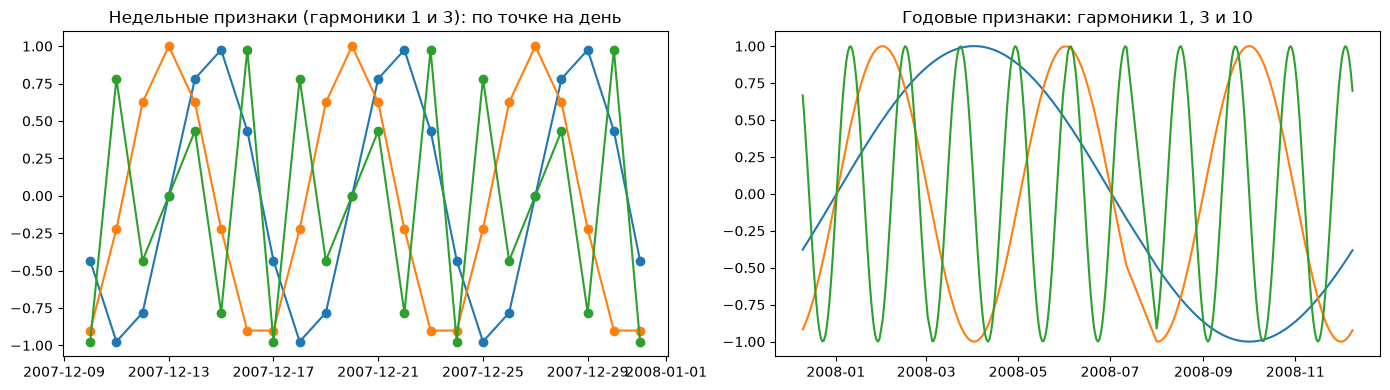

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
first_weeks = m.history["ds"] < "2008-01-01"
ax[0].plot(m.history.loc[first_weeks, "ds"], X.loc[first_weeks, ["weekly_delim_1", "weekly_delim_2", "weekly_delim_5"]], marker="o")
ax[0].set_title("Недельные признаки (гармоники 1 и 3): по точке на день")
first_year = m.history["ds"] < "2008-12-10"
ax[1].plot(m.history.loc[first_year, "ds"], X.loc[first_year, ["yearly_delim_1", "yearly_delim_5", "yearly_delim_19"]])
ax[1].set_title("Годовые признаки: гармоники 1, 3 и 10")
plt.tight_layout()

### 2.3. Праздники $h(t)$ и регрессоры $x(t)$

- Праздник — индикатор «дата попала в окно праздника»; окно `lower_window`/`upper_window` даёт по столбцу на каждый день окна.
- Регрессор — просто ещё один столбец (по умолчанию стандартизованный).

**Ключевой тезис:** всё, кроме тренда, — это столбцы **одной матрицы признаков** $X$, а вся модель — регрессия:
$$\hat y = \underbrace{m + k t + \textstyle\sum_j \delta_j \max(0, t - s_j)}_{\text{тренд}} + X\beta.$$

Проверим: добавим праздники США и посмотрим, что попадёт в модель. `preprocess` готовит данные для Stan, не обучая модель:

In [10]:
m_holidays = Prophet()
m_holidays.add_country_holidays(country_name="US")
stan_data = m_holidays.preprocess(df.copy())

stan_data.X.columns.str.replace(r"_delim_\d+$", "", regex=True).value_counts()

yearly                                  20
weekly                                   6
Christmas Day (observed)_delim_+0        1
Christmas Day_delim_+0                   1
Columbus Day_delim_+0                    1
Independence Day (observed)_delim_+0     1
Independence Day_delim_+0                1
Labor Day_delim_+0                       1
Martin Luther King Jr. Day_delim_+0      1
Memorial Day_delim_+0                    1
New Year's Day (observed)_delim_+0       1
New Year's Day_delim_+0                  1
Thanksgiving Day_delim_+0                1
Veterans Day (observed)_delim_+0         1
Veterans Day_delim_+0                    1
Washington's Birthday_delim_+0           1
Name: count, dtype: int64

20 годовых + 6 недельных столбцов и по одному столбцу на каждый праздник — всё в одной матрице.

### 2.4. Воспроизводим `predict` руками

После обучения параметры лежат в `m.params`: $k$, $m$, вектор $\delta$ (по одному на кандидата в изломы), вектор $\beta$ (по одному на столбец $X$) и $\sigma$. Соберём прогноз на истории по формуле выше:

In [11]:
k, offset = m.params["k"].item(), m.params["m"].item()
delta, beta = m.params["delta"][0], m.params["beta"][0]

trend_manual = (offset + k * t + hinge @ delta) * m.y_scale
seasonal_manual = X.to_numpy() @ beta * m.y_scale

n_hist = len(m.history)
print("тренд совпал:", np.allclose(trend_manual, forecast["trend"][:n_hist]))
print("yhat совпал: ", np.allclose(trend_manual + seasonal_manual, forecast["yhat"][:n_hist]))

тренд совпал: True
yhat совпал:  True


Совпадение до машинной точности: `predict` — это ровно «шарнирный тренд + $X\beta$». Осталось понять, **как оцениваются** $k, m, \delta, \beta$ (раздел 3) и **откуда интервалы** (раздел 4).

## 3. Обучение

### 3.1. Масштабирование

Перед обучением Prophet нормирует данные (`setup_dataframe`, `initialize_scales`):
- $y \to y / \max|y|$ (`scaling='absmax'`, по умолчанию) или $(y - \min y)/(\max y - \min y)$ (`scaling='minmax'`);
- $t \to (t - t_{\min}) / (t_{\max} - t_{\min}) \in [0, 1]$ — поэтому история это $t \in [0, 1]$, а будущее $t > 1$.

Благодаря нормировке одни и те же дефолтные приоры (`changepoint_prior_scale=0.05`, ...) разумны для рядов любого масштаба.

In [12]:
print(f"y_scale = {m.y_scale:.3f}, начало = {m.start.date()}, t_scale = {m.t_scale}")
m.history[["ds", "y", "y_scaled", "t"]].head()

y_scale = 12.847, начало = 2007-12-10, t_scale = 2963 days 00:00:00


,ds,y,y_scaled,t
0,2007-12-10,9.590761,0.746552,0.000000
1,2007-12-11,8.519590,0.663171,0.000337
2,2007-12-12,8.183677,0.637023,0.000675
3,2007-12-13,8.072467,0.628367,0.001012
4,2007-12-14,7.893572,0.614441,0.001350


### 3.2. Stan-модель целиком

Модель записана на вероятностном языке Stan (`prophet/python/stan/prophet.stan`). Блок `model` — это вся модель:

```stan
model {
  // априорные распределения
  k ~ normal(0, 5);
  m ~ normal(0, 5);
  delta ~ double_exponential(0, tau);   // tau = changepoint_prior_scale
  sigma_obs ~ normal(0, 0.5);           // sigma_obs >= 0, т.е. half-normal
  beta ~ normal(0, sigmas);             // sigmas = seasonality/holidays_prior_scale

  // правдоподобие: y ~ N(X_sa*beta + trend .* (1 + X_sm*beta), sigma_obs)
  y ~ normal_id_glm(X_sa, trend .* (1 + X_sm * beta), beta, sigma_obs);
}
```

`X_sa`, `X_sm` — аддитивные и мультипликативные столбцы $X$.

**Приоры ⇔ регуляризация.** По умолчанию Prophet ищет **MAP-оценку** (максимум апостериорной плотности) оптимизатором L-BFGS. Минус логарифм апостериорной плотности:
$$\underbrace{\frac{1}{2\sigma^2}\sum_t (y_t - \hat y_t)^2}_{\text{МНК}} \;+\; \underbrace{\frac{1}{\tau}\sum_j |\delta_j|}_{\text{L1 (Лаплас)}} \;+\; \underbrace{\sum_i \frac{\beta_i^2}{2\sigma_i^2}}_{\text{L2 (нормальное)}} \;+\; \frac{k^2 + m^2}{50} + \dots$$

- Лапласовский приор на $\delta$ — это **Lasso**: большинство изломов зануляется, остаются только нужные. Меньше `changepoint_prior_scale` = $\tau$ ⇒ сильнее штраф ⇒ тренд жёстче.
- Нормальный приор на $\beta$ — это **Ridge**: сезонности/праздники сжимаются к нулю. Дефолт `seasonality_prior_scale=10` на нормированном $y$ почти не штрафует.
- `mcmc_samples > 0` вместо MAP запускает MCMC (NUTS) и возвращает выборку из апостериорного распределения — минуты вместо секунд, зато появляется неопределённость параметров (раздел 4.3).

> **Уточнение к старому ноутбуку 8.1.** Prophet часто описывают как GAM, обучаемую backfitting'ом, со ссылкой на теорему Колмогорова–Арнольда. Это неверно: Prophet не использует ни теорему Колмогорова–Арнольда, ни backfitting. Все компоненты оцениваются **одновременно** одной задачей оптимизации (или MCMC) в Stan. С GAM его роднит лишь аддитивная структура.

Посмотрим на оценённые изломы: L1-приор сделал вектор $\delta$ разреженным.

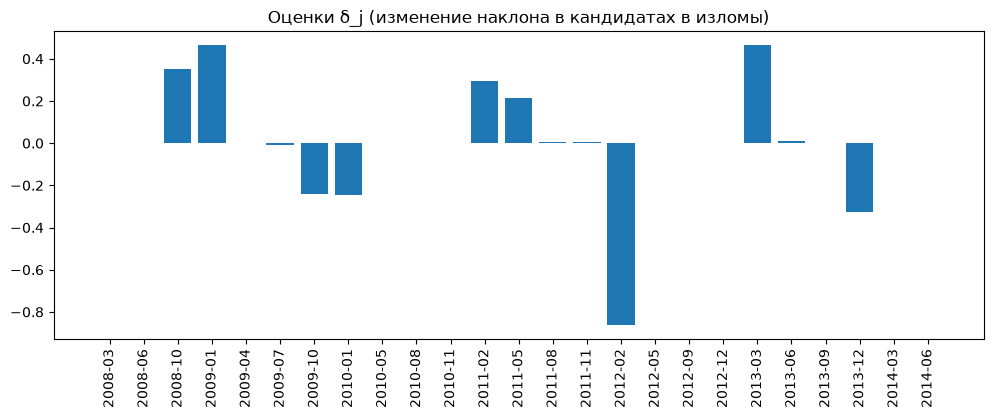

In [13]:
fig, ax = plt.subplots()
ax.bar(m.changepoints.dt.strftime("%Y-%m"), delta)
ax.set_title("Оценки δ_j (изменение наклона в кандидатах в изломы)")
ax.tick_params(axis="x", rotation=90)

### 3.3. Собираем Prophet руками через `sklearn`

Раз модель — регрессия, её можно обучить обычными средствами. Матрица признаков: $[\,t,\; \max(0, t - s_j),\; X\,]$, целевая — нормированный $y$.

Перепишем MAP-задачу в терминах `sklearn.Lasso`, который минимизирует $\frac{1}{2n}\|y - Dw\|^2 + \alpha\|w\|_1$: умножаем целевую функцию на $\sigma^2/n$ и получаем $\alpha = \sigma^2 / (n\,\tau)$ ($\sigma$ возьмём из обученного Prophet). Для сравнения — МНК без штрафа.

In [14]:
design = np.column_stack([t, hinge, X])
y_scaled = m.history["y_scaled"].to_numpy()

sigma = m.params["sigma_obs"].item()
alpha = sigma**2 / (n_hist * m.changepoint_prior_scale)

models = {
    "МНК": LinearRegression().fit(design, y_scaled),
    "Lasso": Lasso(alpha=alpha, max_iter=100_000).fit(design, y_scaled),
}
n_cp = len(changepoints_t)
deltas = pd.DataFrame(
    {name: model.coef_[1 : 1 + n_cp] for name, model in models.items()} | {"Prophet": delta},
    index=m.changepoints.dt.strftime("%Y-%m"),
)
deltas.round(3).T

ds,2008-03,2008-06,2008-10,2009-01,2009-04,2009-07,2009-10,2010-01,2010-05,2010-08,...,2012-02,2012-05,2012-09,2012-12,2013-03,2013-06,2013-09,2013-12,2014-03,2014-06
МНК,-0.236,-1.412,1.643,1.243,-1.404,-0.085,1.508,-2.975,1.828,0.386,...,-6.497,2.708,-0.409,-0.005,0.262,0.303,0.688,-1.633,0.481,0.056
Lasso,-0.256,-0.000,0.172,0.620,-0.000,-0.000,-0.312,-0.190,0.000,0.000,...,-0.914,-0.000,-0.000,0.000,0.498,0.000,-0.000,-0.339,-0.000,-0.000
Prophet,-0.000,-0.000,0.353,0.464,0.000,-0.010,-0.242,-0.246,-0.000,0.000,...,-0.863,-0.000,-0.000,-0.000,0.464,0.010,-0.000,-0.328,-0.000,-0.000


МНК: RMSE до yhat Prophet = 0.1493, ненулевых δ = 25
Lasso: RMSE до yhat Prophet = 0.0154, ненулевых δ = 11


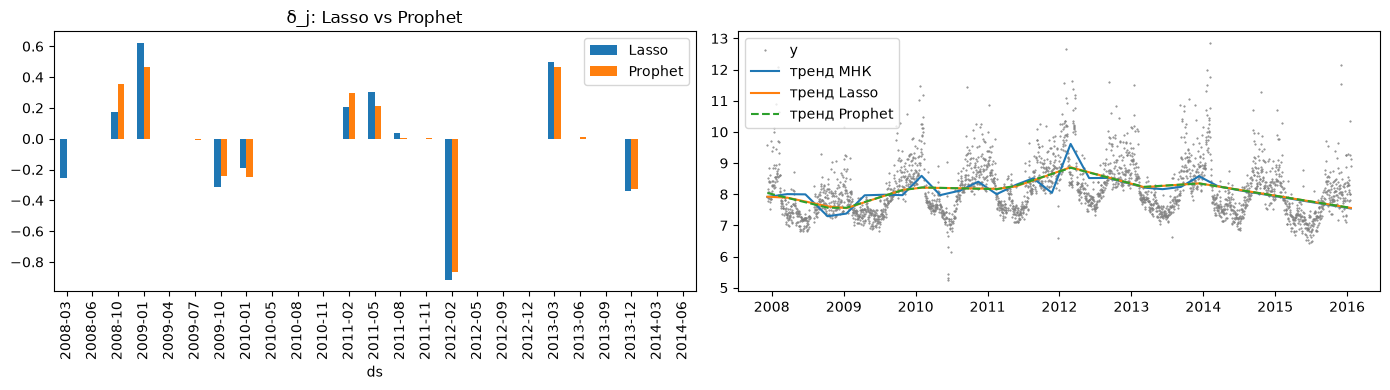

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
deltas[["Lasso", "Prophet"]].plot.bar(ax=ax[0], title="δ_j: Lasso vs Prophet")
ax[1].plot(m.history["ds"], m.history["y"], ".", ms=1, color="grey", label="y")
for name, model in models.items():
    w = model.coef_
    trend = (model.intercept_ + design[:, : 1 + n_cp] @ w[: 1 + n_cp]) * m.y_scale
    ax[1].plot(m.history["ds"], trend, label=f"тренд {name}")
ax[1].plot(m.history["ds"], forecast["trend"][:n_hist], "--", label="тренд Prophet")
ax[1].legend()
plt.tight_layout()

for name, model in models.items():
    rmse = np.sqrt(np.mean((model.predict(design) * m.y_scale - forecast["yhat"][:n_hist]) ** 2))
    print(f"{name}: RMSE до yhat Prophet = {rmse:.4f}, ненулевых δ = {(np.abs(model.coef_[1:1 + n_cp]) > 1e-3).sum()}")

- **МНК** использует все 25 изломов и делает их огромными: тренд начинает «объяснять» сезонность и шум.
- **Lasso** с $\alpha$, выведенным из приора, почти повторяет Prophet: те же изломы, тот же тренд.

Почему совпадение не точное:
- Lasso штрафует L1 **все** коэффициенты (включая $k$ и сезонные $\beta$), а у Prophet на $\beta$ слабый L2-приор, на $k$ — почти плоский $N(0, 5)$;
- Prophet оценивает $\sigma$ совместно с остальными параметрами, а мы подставили готовую;
- разные оптимизаторы.

Вывод: **Prophet = регрессия с разными штрафами на разные блоки признаков**. Гиперпараметры `*_prior_scale` — это силы регуляризации.

## 4. Как получаются прогнозы и интервалы

### 4.1. Точечный прогноз

- **Тренд** продолжается прямой с наклоном последнего сегмента $k + \sum_j \delta_j$ (новых изломов в точечном прогнозе нет).
- **Сезонности и праздники** — детерминированные функции даты: строим $X$ для будущих дат и умножаем на $\beta$.
- **Регрессоры** нужно знать в будущем — это ограничение мы обсудим в ноутбуке 3.

In [16]:
slope_per_year = (k + delta.sum()) * m.y_scale / m.t_scale.days * 365
print(f"наклон последнего сегмента: {slope_per_year:.3f} в год")
print(f"наклон тренда в конце прогноза: {forecast['trend'].diff().iloc[-1] * 365:.3f} в год")

наклон последнего сегмента: -0.371 в год
наклон тренда в конце прогноза: -0.371 в год


### 4.2. Интервалы: три источника неопределённости

1. **Шум** $\varepsilon \sim N(0, \sigma^2)$.
2. **Неопределённость тренда** — главный источник. Prophet предполагает, что *в будущем изломы будут происходить так же часто и такой же силы, как в истории* (`sample_predictive_trend`):
   - число будущих изломов $\sim \text{Poisson}\big(S \cdot (T - 1)\big)$, где $T - 1$ — длина горизонта в единицах нормированного $t$;
   - их величины $\delta_{new} \sim \text{Laplace}\big(0,\; \text{mean}|\delta|\big)$.
3. **Неопределённость параметров** ($k, m, \delta, \beta, \sigma$) — **только при MCMC**: при MAP параметры — одна точка.

Prophet генерирует `uncertainty_samples=1000` траекторий будущего и берёт квантили (`interval_width=0.8` ⇒ 10 % и 90 %). Сами траектории доступны через `predictive_samples`:

{'yhat': (3270, 1000), 'trend': (3270, 1000)}


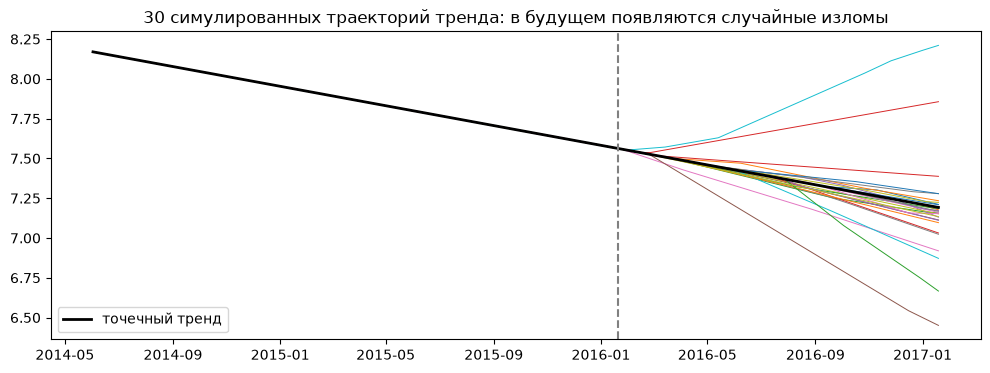

In [17]:
samples = m.predictive_samples(future)
print({key: value.shape for key, value in samples.items()})

recent = future["ds"] > "2014-06-01"
fig, ax = plt.subplots()
ax.plot(future.loc[recent, "ds"], samples["trend"][recent, :30], lw=0.7)
ax.plot(future.loc[recent, "ds"], forecast.loc[recent, "trend"], "k", lw=2, label="точечный тренд")
ax.axvline(df["ds"].max(), color="grey", ls="--")
ax.set_title("30 симулированных траекторий тренда: в будущем появляются случайные изломы")
ax.legend();

`interval_width` меняет только квантили, а не `yhat` — перестраивать модель не нужно, достаточно взять другие квантили из тех же траекторий:

In [18]:
horizon = future["ds"] > df["ds"].max()
for level in [0.8, 0.95]:
    lower, upper = np.quantile(samples["yhat"][horizon], [(1 - level) / 2, (1 + level) / 2], axis=1)
    print(f"{level:.0%}: средняя ширина интервала на горизонте = {np.mean(upper - lower):.2f}")

80%: средняя ширина интервала на горизонте = 1.30
95%: средняя ширина интервала на горизонте = 1.99


**Следствие:** чем гибче тренд в истории (больше `changepoint_prior_scale`), тем больше и сильнее изломов модель ожидает в будущем ⇒ тем шире интервал. Документация предлагает использовать это как индикатор переобучения тренда.

mean|δ| (масштаб будущих изломов): 0.1399 vs 0.9901


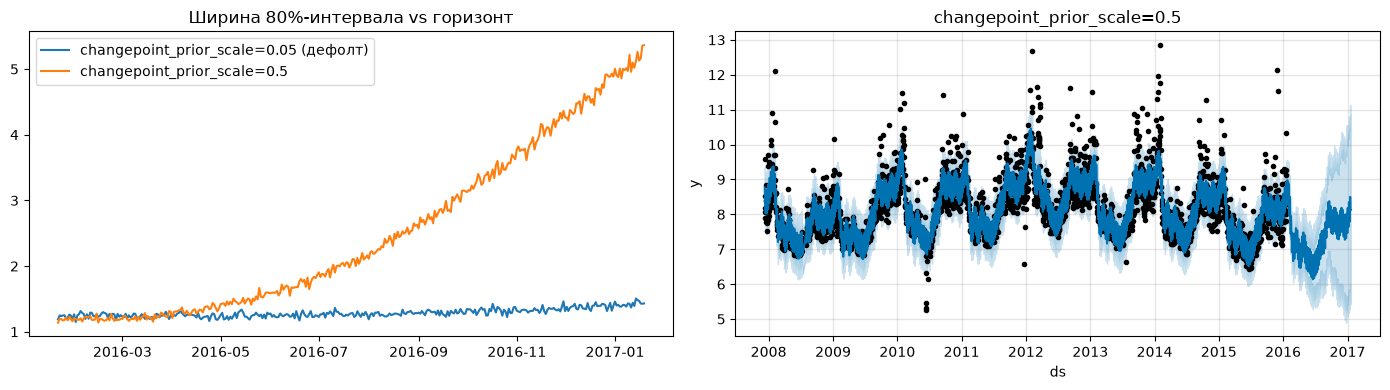

In [19]:
m_flexible = Prophet(changepoint_prior_scale=0.5).fit(df)
forecast_flexible = m_flexible.predict(future)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for name, fc in [("0.05 (дефолт)", forecast), ("0.5", forecast_flexible)]:
    ax[0].plot(fc.loc[horizon, "ds"], (fc["yhat_upper"] - fc["yhat_lower"])[horizon], label=f"changepoint_prior_scale={name}")
ax[0].set_title("Ширина 80%-интервала vs горизонт")
ax[0].legend()
m_flexible.plot(forecast_flexible, ax=ax[1])
ax[1].set_title("changepoint_prior_scale=0.5")
plt.tight_layout()

print("mean|δ| (масштаб будущих изломов):", np.abs(delta).mean().round(4), "vs", np.abs(m_flexible.params["delta"]).mean().round(4))

> Документация честно предупреждает: предположение «будущее как прошлое» скорее всего неверно, поэтому **не стоит ожидать точного покрытия** интервалов. Покрытие проверим кросс-валидацией в ноутбуке 4.

### 4.3. Неопределённость сезонности: MCMC

При MAP сезонность — точечная оценка, интервала у неё нет. Чтобы учесть неопределённость $\beta$, нужна полная байесовская выборка `mcmc_samples` (как в документации, на первых шести месяцах ряда, — годовая сезонность здесь отключится автоматически):

{'k': (600,), 'delta': (600, 25), 'beta': (600, 6), 'sigma_obs': (600,)}


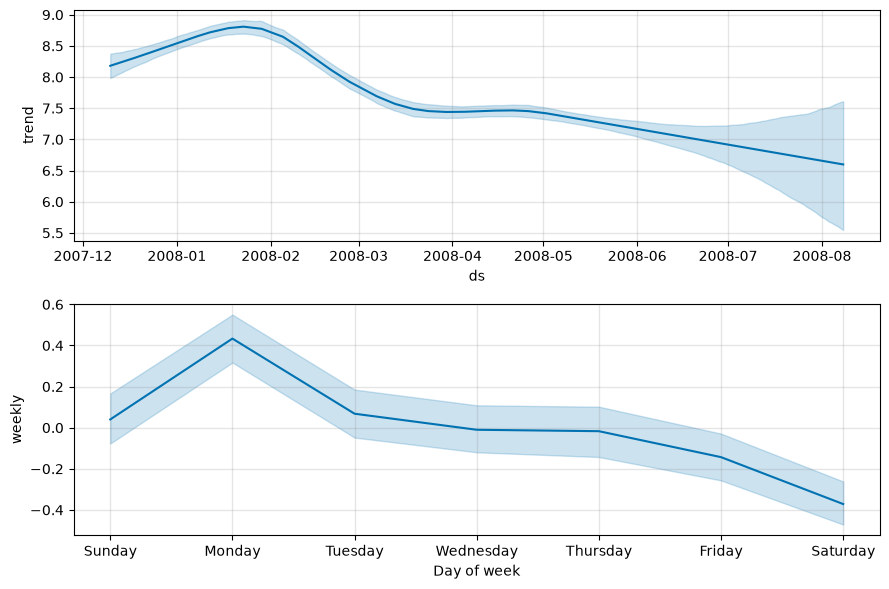

In [20]:
df_short = df[df["ds"] < "2008-06-10"]
m_mcmc = Prophet(mcmc_samples=300).fit(df_short, show_progress=False)
forecast_mcmc = m_mcmc.predict(m_mcmc.make_future_dataframe(periods=60))

print({key: m_mcmc.params[key].shape for key in ["k", "delta", "beta", "sigma_obs"]})
fig = m_mcmc.plot_components(forecast_mcmc)

Теперь у каждого параметра 600 значений (4 цепи × 150 итераций после прогрева) — выборка из постериора, и у недельной сезонности появилась полоса неопределённости.

### 4.4. Выбросы ломают интервалы

Пример из документации (`outliers`): просмотры страницы Википедии о языке R с блоком испорченных данных в 2010 году.

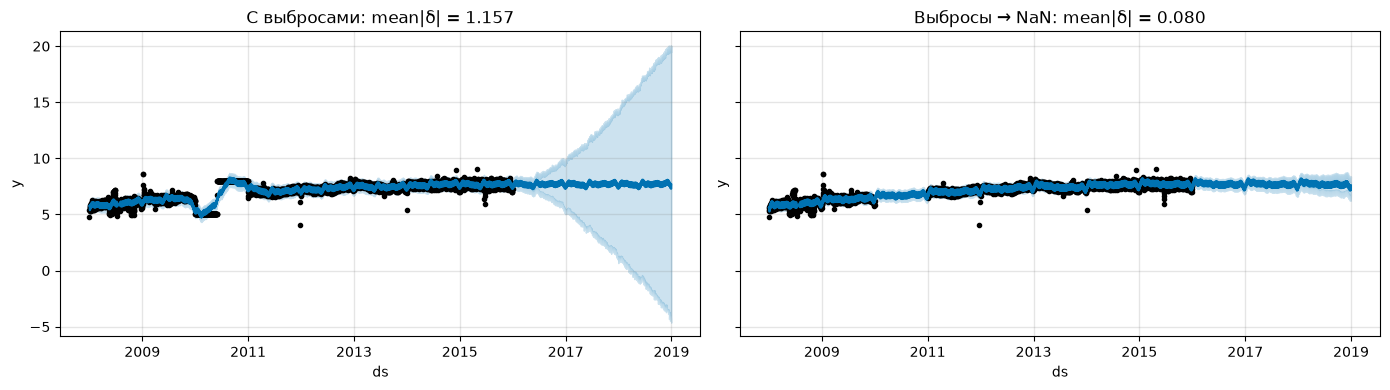

In [21]:
df_r = pd.read_csv("data/example_wp_log_R_outliers1.csv", parse_dates=["ds"])
m_r = Prophet().fit(df_r)
future_r = m_r.make_future_dataframe(periods=1096)

df_r_clean = df_r.copy()
df_r_clean.loc[(df_r_clean["ds"] > "2010-01-01") & (df_r_clean["ds"] < "2011-01-01"), "y"] = np.nan
m_r_clean = Prophet().fit(df_r_clean)

fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for axis, model, title in [(ax[0], m_r, "С выбросами"), (ax[1], m_r_clean, "Выбросы → NaN")]:
    model.plot(model.predict(future_r), ax=axis)
    axis.set_title(f"{title}: mean|δ| = {np.abs(model.params['delta']).mean():.3f}")
plt.tight_layout()

Prophet «объясняет» блок выбросов изломами тренда ⇒ $\text{mean}|\delta|$ растёт ⇒ в будущем ожидаются такие же сильные изломы ⇒ интервал становится огромным.

**Лечение — удалить выбросы (заменить на `NaN`)**: Prophet регрессирует на дату, пропуски ему не мешают, а для дат из `future` прогноз всё равно будет построен.

## 5. Сводная таблица гиперпараметров

| Ручка | Что меняет в модели | Дефолт | Когда трогать |
|---|---|---|---|
| `changepoint_prior_scale` | масштаб Лапласа $\tau$ для $\delta$ (сила L1) | 0.05 | самая важная; тюнить по сетке [0.001, 0.5] в лог-шкале |
| `seasonality_prior_scale` | масштаб $\sigma_i$ нормального приора для сезонных $\beta$ (сила L2) | 10 | если сезонность переобучена; [0.01, 10] |
| `holidays_prior_scale` | то же для праздников | 10 | [0.01, 10] |
| `seasonality_mode` | столбцы $X$ идут в `X_sa` или в `X_sm` | `additive` | амплитуда сезонности растёт с уровнем ряда |
| `changepoint_range` | доля истории под сетку кандидатов $s_j$ | 0.8 | изломы в самом конце ряда; по CV тюнится плохо |
| `n_changepoints` | размер сетки кандидатов $S$ | 25 | обычно не трогать — регулировать через `changepoint_prior_scale` |
| `changepoints` | ручные положения $s_j$ | авто | известные даты смены режима |
| `growth` | вид $g(t)$: `linear` / `logistic` / `flat` | `linear` | есть насыщение (`cap`) или тренда нет |
| `yearly/weekly/daily_seasonality` | число столбцов $X$ (`fourier_order`) | `auto` (10 / 3 / 4) | лучше не выключать, а ослаблять приором |
| `mcmc_samples` | MAP → MCMC, неопределённость параметров | 0 | нужна неопределённость сезонности; короткий ряд |
| `interval_width` | квантили симулированных траекторий | 0.8 | не влияет на `yhat`, не тюнится |
| `uncertainty_samples` | число траекторий | 1000 | если интервалы «рваные»; 0 — выключить интервалы |

(Рекомендации — по разделу *Hyperparameter tuning* документации `diagnostics`.)

## Итоги

- Prophet — регрессия на признаках времени: шарнирный тренд $\max(0, t - s_j)$ + Фурье-признаки + индикаторы праздников + регрессоры, всё кроме тренда — одна матрица $X$.
- Обучение — MAP в Stan: приор Лапласа на изломы = L1 (разреженные изломы), нормальный приор на $\beta$ = L2. Модель воспроизводится `sklearn.Lasso` с $\alpha = \sigma^2/(n\tau)$.
- Прогноз тренда — прямая с последним наклоном; интервалы — симуляция будущих изломов «как в истории» + шум; неопределённость параметров — только при MCMC.
- Интервалы расширяются с горизонтом и с `changepoint_prior_scale`, раздуваются от выбросов; их покрытие нужно проверять (ноутбук 4).

Дальше (ноутбук 2): каждая ручка модели на кейсах из документации — изломы, насыщение, сезонности, мультипликативность, праздники.